# Tiền xử lý dữ liệu Online Retail II (phiên bản 1)

**Người phụ trách:** thành viên 1 (MSSV 1) — tiền xử lý dữ liệu: giá trị thiếu, hóa đơn hủy, ngoại lai.

**Quy trình của notebook:** (1) xem dữ liệu (shape, info, describe số/không số, độ lệch, tứ phân vị, kích thước) →
(2) vẽ hình để nhận xét (histogram, countplot, boxplot) → (3) ghi nhận xét và **đề xuất phương án xử lý** →
(4) xử lý theo phương án đã đề xuất → (5) kiểm tra lại và lưu vào `data/processed/`.

> Dữ liệu gốc trong `data/raw/` **không bị sửa**. Mọi bước chạy trên bản sao.

## 1. Chuẩn bị môi trường và đọc dữ liệu

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Tìm thư mục gốc dự án (thư mục chứa data/raw) dù chạy từ đâu
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
sys.path.insert(0, str(ROOT / "src"))
import preprocessing as pp

pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 90, "axes.titlesize": 11})
print("Thư mục gốc:", ROOT)

Thư mục gốc: /home/claude/SGU-ML-High-Value-Customer-Prediction-main/project


In [2]:
# Đọc 2 sheet và gộp lại (mất khoảng 1 phút vì file Excel lớn)
raw = pp.load_raw(ROOT / "data" / "raw" / "online_retail_II.xlsx")
ORIG_COLS = [c for c in raw.columns if c != "Sheet"]
print(raw["Sheet"].value_counts().to_string())

Sheet
Year 2010-2011    541910
Year 2009-2010    525461


## 2. Xem tổng quan dữ liệu

### 2.1. Kích thước (shape), kiểu dữ liệu (info) và dung lượng

In [3]:
print("shape:", raw.shape)
raw.info(memory_usage="deep")
display(raw.head())
display(raw.tail(3))

shape: (1067371, 9)


<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 9 columns):
 #   Column       Non-Null Count    Dtype         
---  ------       --------------    -----         
 0   Invoice      1067371 non-null  object        
 1   StockCode    1067371 non-null  object        
 2   Description  1062989 non-null  object        
 3   Quantity     1067371 non-null  int64         
 4   InvoiceDate  1067371 non-null  datetime64[us]
 5   Price        1067371 non-null  float64       
 6   Customer ID  824364 non-null   float64       
 7   Country      1067371 non-null  str           
 8   Sheet        1067371 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(2)
memory usage: 313.2 MB


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sheet
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,"13,085.000",United Kingdom,Year 2009-2010
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,"13,085.000",United Kingdom,Year 2009-2010
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,"13,085.000",United Kingdom,Year 2009-2010
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,"13,085.000",United Kingdom,Year 2009-2010
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,"13,085.000",United Kingdom,Year 2009-2010


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Sheet
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.150,"12,680.000",France,Year 2010-2011
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.950,"12,680.000",France,Year 2010-2011
1067370,581587,POST,POSTAGE,1,2011-12-09 12:50:00,18.000,"12,680.000",France,Year 2010-2011


**Nhận xét:** mỗi dòng là một *mặt hàng trên một hóa đơn* (không phải một khách hàng, cũng không phải một hóa đơn hoàn chỉnh).
Hai sheet (2009-2010 và 2010-2011) có cùng 8 cột nên gộp được. `Customer ID` đang là `float64` vì có giá trị thiếu (NaN),
sau khi xử lý thiếu sẽ đổi sang số nguyên. `Invoice` và `StockCode` là chuỗi vì chứa chữ (tiền tố `C`, hậu tố chữ cái).

### 2.2. Thống kê mô tả: cột số và cột không phải số

In [4]:
num_cols = ["Quantity", "Price", "Customer ID"]
display(Markdown("**Cột số** (`Customer ID` chỉ là mã định danh, đưa vào để kiểm tra chứ không diễn giải trung bình)"))
display(raw[num_cols].describe(percentiles=[.01, .25, .5, .75, .99]).T)

display(Markdown("**Cột không phải số / thời gian**"))
display(raw[["Invoice", "StockCode", "Description", "Country"]].describe().T)
display(raw[["InvoiceDate"]].describe().T)

**Cột số** (`Customer ID` chỉ là mã định danh, đưa vào để kiểm tra chứ không diễn giải trung bình)

,count,mean,std,min,1%,25%,50%,75%,99%,max
Quantity,"1,067,371.000",9.939,172.706,"-80,995.000",-3.000,1.000,3.000,10.000,100.000,"80,995.000"
Price,"1,067,371.000",4.649,123.553,"-53,594.360",0.210,1.250,2.100,4.150,18.000,"38,970.000"
Customer ID,"824,364.000","15,324.639","1,697.464","12,346.000","12,422.000","13,975.000","15,255.000","16,797.000","18,207.000","18,287.000"


**Cột không phải số / thời gian**

,count,unique,top,freq
Invoice,1067371,53628,537434,1350
StockCode,1067371,5305,85123A,5829
Description,1062989,5698,WHITE HANGING HEART T-LIGHT HOLDER,5918
Country,1067371,43,United Kingdom,981330


,count,mean,min,25%,50%,75%,max
InvoiceDate,1067371,2011-01-02 21:13:55.394029,2009-12-01 07:45:00,2010-07-09 09:46:00,2010-12-07 15:28:00,2011-07-22 10:23:00,2011-12-09 12:50:00


### 2.3. Độ lệch (skew), kurtosis, tứ phân vị (Q1, Q3, IQR) và hàng rào ngoại lai

In [5]:
rows = []
for col in ["Quantity", "Price"]:
    s = raw[col]
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    rows.append({
        "Cột": col, "Skew": s.skew(), "Kurtosis": s.kurt(),
        "Q1": q1, "Median": s.median(), "Q3": q3, "IQR": iqr,
        "Hàng rào dưới": lo, "Hàng rào trên": hi,
        "Số dòng ngoài hàng rào": int(((s < lo) | (s > hi)).sum()),
        "% ngoài hàng rào": 100 * ((s < lo) | (s > hi)).mean(),
        "Min": s.min(), "Max": s.max(),
    })
iqr_raw = pd.DataFrame(rows).set_index("Cột")
display(iqr_raw.T)

Cột,Quantity,Price
Skew,3.996,-69.165
Kurtosis,"155,059.693","73,751.829"
Q1,1.000,1.250
Median,3.000,2.100
Q3,10.000,4.150
IQR,9.000,2.900
Hàng rào dưới,-12.500,-3.100
Hàng rào trên,23.500,8.500
Số dòng ngoài hàng rào,"116,489.000","68,105.000"
% ngoài hàng rào,10.914,6.381


**Nhận xét:**
- `Quantity` và `Price` đều có **kurtosis cực lớn** và `Max` cách xa Q3 hàng trăm lần → phân phối **lệch và đuôi rất dài**.
- `Skew` của `Price` ra **âm lớn** là do 5 dòng giá âm cực trị (`Adjust bad debt`, tới -53.594), không phải do giá hàng thật lệch trái → cần xử lý dòng này trước rồi mới đọc lại độ lệch.
- Giá trị `Quantity` âm là hóa đơn hủy/trả hàng; giá trị `Price = 0` là dòng tặng/điều chỉnh. Đây là lỗi *nghiệp vụ*, không phải ngoại lai thống kê.

### 2.4. Giá trị thiếu

,Số thiếu,% thiếu
Invoice,0,0.000
StockCode,0,0.000
Description,4382,0.411
Quantity,0,0.000
InvoiceDate,0,0.000
Price,0,0.000
Customer ID,243007,22.767
Country,0,0.000


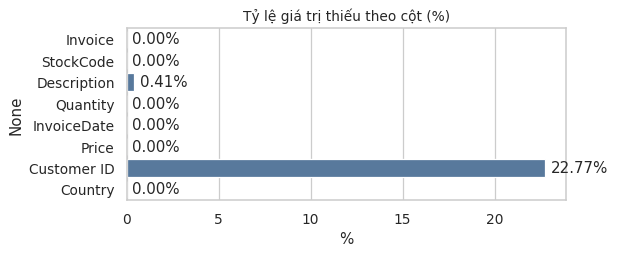

In [6]:
missing = pd.DataFrame({
    "Số thiếu": raw[ORIG_COLS].isna().sum(),
    "% thiếu": raw[ORIG_COLS].isna().mean() * 100,
})
display(missing)

fig, ax = plt.subplots(figsize=(7, 3))
sns.barplot(x=missing["% thiếu"].values, y=missing.index, color="#4C78A8", ax=ax)
ax.set_title("Tỷ lệ giá trị thiếu theo cột (%)"); ax.set_xlabel("%")
for i, v in enumerate(missing["% thiếu"]):
    ax.text(v + 0.3, i, f"{v:.2f}%", va="center")
plt.tight_layout(); plt.show()

In [7]:
nocust = raw[raw["Customer ID"].isna()]
is_c = raw["Invoice"].astype(str).str.startswith("C")
print("Thiếu Customer ID:", len(nocust), f"({len(nocust)/len(raw):.2%})")
print("Tỷ lệ thiếu Customer ID trong hóa đơn hủy  :", f"{raw.loc[is_c, 'Customer ID'].isna().mean():.2%}")
print("Tỷ lệ thiếu Customer ID trong hóa đơn thường:", f"{raw.loc[~is_c, 'Customer ID'].isna().mean():.2%}")
print("Thiếu Description:", int(raw["Description"].isna().sum()),
      "| trong đó Price == 0:", int((raw["Description"].isna() & raw["Price"].eq(0)).sum()),
      "| có Customer ID:", int((raw["Description"].isna() & raw["Customer ID"].notna()).sum()))
display(nocust["Country"].value_counts().head(5).to_frame("dòng thiếu Customer ID"))
display(nocust["StockCode"].astype(str).value_counts().head(5).to_frame("mã hàng phổ biến nhất khi thiếu ID"))

Thiếu Customer ID: 243007 (22.77%)
Tỷ lệ thiếu Customer ID trong hóa đơn hủy  : 3.85%
Tỷ lệ thiếu Customer ID trong hóa đơn thường: 23.12%
Thiếu Description: 4382 | trong đó Price == 0: 4382 | có Customer ID: 0


,dòng thiếu Customer ID
Country,
United Kingdom,240029
EIRE,1671
Hong Kong,364
Unspecified,232
France,128


,mã hàng phổ biến nhất khi thiếu ID
StockCode,
DOT,1430
85099B,770
22423,647
21212,639
21931,635


**Nhận xét:**
- `Customer ID` thiếu khoảng **22,8%** số dòng. RFM tính ở **cấp khách hàng** nên dòng không có mã khách không thể gán cho ai.
  Không nên điền (mean/mode/giá trị giả) vì sẽ gộp nhiều người mua khác nhau thành một "khách hàng" ảo, làm sai Frequency và Monetary.
- `Description` thiếu hoàn toàn trùng với dòng `Price = 0` và không có `Customer ID` → vốn đã nằm trong nhóm dòng sẽ bị loại.

**Đề xuất:** loại dòng thiếu `Customer ID` khỏi dữ liệu dùng cho phân cụm (ghi lại số dòng bị loại).

### 2.5. Dòng trùng lặp

In [8]:
key = pd.util.hash_pandas_object(raw[ORIG_COLS], index=False)
dup_mask = raw.duplicated(subset=ORIG_COLS, keep="first")
first_sheet = raw.groupby(key)["Sheet"].transform("first")
cross_sheet = dup_mask & (raw["Sheet"] != first_sheet)

print("Dòng trùng hoàn toàn (giữ bản đầu tiên):", int(dup_mask.sum()), f"({dup_mask.mean():.2%})")
print(" - Trùng giữa 2 sheet (khoảng chồng lấn 01-09/12/2010):", int(cross_sheet.sum()))
print(" - Trùng trong cùng 1 sheet                          :", int((dup_mask & ~cross_sheet).sum()))
ov = raw[raw["Sheet"] == "Year 2010-2011"]["InvoiceDate"].min(), raw[raw["Sheet"] == "Year 2009-2010"]["InvoiceDate"].max()
print("Sheet 2010-2011 bắt đầu:", ov[0], "| Sheet 2009-2010 kết thúc:", ov[1])

Dòng trùng hoàn toàn (giữ bản đầu tiên): 34335 (3.22%)
 - Trùng giữa 2 sheet (khoảng chồng lấn 01-09/12/2010): 22523
 - Trùng trong cùng 1 sheet                          : 11812
Sheet 2010-2011 bắt đầu: 2010-12-01 08:26:00 | Sheet 2009-2010 kết thúc: 2010-12-09 20:01:00


**Nhận xét:** hai sheet **chồng lấn nhau** khoảng 9 ngày đầu tháng 12/2010 nên cùng một giao dịch xuất hiện hai lần — đây chắc chắn là bản sao.
Phần trùng trong cùng một sheet có thể là dòng quét hai lần; vì trùng cả giờ-phút, mã hóa đơn, mã hàng và giá nên vẫn coi là bản sao.

**Đề xuất:** `drop_duplicates` trên 8 cột gốc (không tính cột `Sheet`).

### 2.6. Hóa đơn hủy, số lượng/giá không dương và mã hàng đặc biệt

In [9]:
inv = raw["Invoice"].astype(str)
stock = raw["StockCode"].astype(str).str.strip().str.upper()
checks = {
    "Hóa đơn hủy (tiền tố C)": is_c,
    "Quantity < 0": raw["Quantity"] < 0,
    "Quantity < 0 nhưng KHÔNG có tiền tố C": (raw["Quantity"] < 0) & ~is_c,
    "Quantity == 0": raw["Quantity"] == 0,
    "Price == 0": raw["Price"] == 0,
    "Price < 0": raw["Price"] < 0,
    "Mã hóa đơn lạ (không phải 6 chữ số, không phải C+6 số)": ~inv.str.fullmatch(r"C?\d{6}"),
    "Mã hàng không phải dạng sản phẩm (5 số + chữ)": ~stock.str.fullmatch(r"\d{5}[A-Z]{0,3}"),
}
cnt = pd.DataFrame({"Số dòng": {k: int(v.sum()) for k, v in checks.items()}})
cnt["% tổng dòng"] = cnt["Số dòng"] / len(raw) * 100
display(cnt)

,Số dòng,% tổng dòng
Hóa đơn hủy (tiền tố C),19494,1.826
Quantity < 0,22950,2.150
Quantity < 0 nhưng KHÔNG có tiền tố C,3457,0.324
Quantity == 0,0,0.000
Price == 0,6202,0.581
Price < 0,5,0.000
"Mã hóa đơn lạ (không phải 6 chữ số, không phải C+6 số)",6,0.001
Mã hàng không phải dạng sản phẩm (5 số + chữ),6093,0.571


In [10]:
display(Markdown("**Hóa đơn lạ (tiền tố `A`)**"))
display(raw[~inv.str.fullmatch(r"C?\d{6}")][["Invoice", "StockCode", "Description", "Quantity", "Price"]])

display(Markdown("**Mô tả của dòng Quantity <= 0 mà không phải hóa đơn hủy** (ghi chú kho, không phải bán hàng)"))
display(raw[(raw["Quantity"] <= 0) & ~is_c]["Description"].value_counts(dropna=False).head(8).to_frame("số dòng"))

display(Markdown("**Mã hàng không phải sản phẩm**"))
odd = raw.assign(StockCode=stock)[~stock.str.fullmatch(r"\d{5}[A-Z]{0,3}")]
display(odd.groupby("StockCode").agg(
    số_dòng=("Invoice", "size"),
    có_CustomerID=("Customer ID", lambda s: int(s.notna().sum())),
    giá_TB=("Price", "mean"),
    mô_tả=("Description", lambda s: s.dropna().iloc[0] if s.notna().any() else None),
).sort_values("số_dòng", ascending=False).head(15))

**Hóa đơn lạ (tiền tố `A`)**

,Invoice,StockCode,Description,Quantity,Price
179403,A506401,B,Adjust bad debt,1,"-53,594.360"
276274,A516228,B,Adjust bad debt,1,"-44,031.790"
403472,A528059,B,Adjust bad debt,1,"-38,925.870"
825443,A563185,B,Adjust bad debt,1,"11,062.060"
825444,A563186,B,Adjust bad debt,1,"-11,062.060"
825445,A563187,B,Adjust bad debt,1,"-11,062.060"


**Mô tả của dòng Quantity <= 0 mà không phải hóa đơn hủy** (ghi chú kho, không phải bán hàng)

,số dòng
Description,
NaN,2689
check,123
damages,84
?,83
damaged,78
missing,27
sold as set on dotcom,20
Damaged,17


**Mã hàng không phải sản phẩm**

,số_dòng,có_CustomerID,giá_TB,mô_tả
StockCode,,,,
POST,2122,2019,32.623,POSTAGE
DOT,1446,16,223.145,DOTCOM POSTAGE
M,1426,1115,526.933,Manual
C2,282,259,49.461,CARRIAGE
D,177,174,72.867,Discount
S,104,0,60.957,SAMPLES
BANK CHARGES,102,38,359.034,Bank Charges
ADJUST,67,61,163.591,Adjustment by john on 26/01/2010 16
AMAZONFEE,43,0,"7,646.089",AMAZON FEE


**Nhận xét:**
- Có ~19,5 nghìn dòng thuộc hóa đơn hủy (`C...`); ngoài ra còn ~3,5 nghìn dòng `Quantity <= 0` **không** có tiền tố `C`, mô tả là `damaged`, `check`, `missing`... → bút toán kho, không phải mua bán.
- Hóa đơn tiền tố `A` (`Adjust bad debt`) có giá âm hàng chục nghìn bảng, là điều chỉnh sổ sách.
- Các mã `POST`, `DOT`, `M`, `C2`, `D`, `S`, `BANK CHARGES`, `ADJUST`, `AMAZONFEE`, `CRUK`, `TEST001`... là **phí/bưu phí/chiết khấu/hàng thử**, giá trung bình rất cao (hàng chục đến hàng nghìn) nên nếu giữ sẽ làm *Monetary* sai lệch nặng, còn *Frequency* bị thổi phồng bởi các bút toán không phải mua hàng.

**Đề xuất:**
1. Bỏ các mã hàng dịch vụ liệt kê trên.
2. **Tách** hóa đơn hủy (có `C`) sang bảng riêng thay vì xóa mất: bảng này giữ lại để thành viên 2 có thể tính đặc trưng "tỷ lệ hoàn trả" trong RFM mở rộng; còn bảng bán hàng chỉ gồm giao dịch mua.
3. Bỏ dòng bán còn lại có `Quantity <= 0` hoặc `Price <= 0`.

### 2.7. Phân phối theo quốc gia (countplot) và thời gian

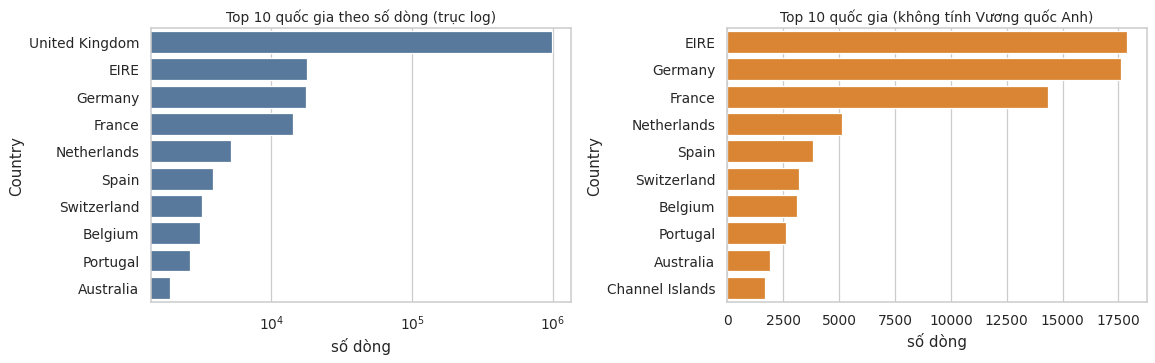

Số quốc gia: 43 | tỷ trọng UK: 91.9%
Khách hàng xuất hiện ở > 1 quốc gia: 13 / 5942


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
top = raw["Country"].value_counts().head(10)
sns.barplot(x=top.values, y=top.index, color="#4C78A8", ax=axes[0])
axes[0].set_xscale("log"); axes[0].set_title("Top 10 quốc gia theo số dòng (trục log)"); axes[0].set_xlabel("số dòng")

top_no_uk = raw.loc[raw["Country"] != "United Kingdom", "Country"].value_counts().head(10)
sns.barplot(x=top_no_uk.values, y=top_no_uk.index, color="#F58518", ax=axes[1])
axes[1].set_title("Top 10 quốc gia (không tính Vương quốc Anh)"); axes[1].set_xlabel("số dòng")
plt.tight_layout(); plt.show()

print("Số quốc gia:", raw["Country"].nunique(), "| tỷ trọng UK:", f"{(raw['Country']=='United Kingdom').mean():.1%}")
cc = raw.dropna(subset=["Customer ID"]).groupby("Customer ID")["Country"].nunique()
print("Khách hàng xuất hiện ở > 1 quốc gia:", int((cc > 1).sum()), "/", len(cc))

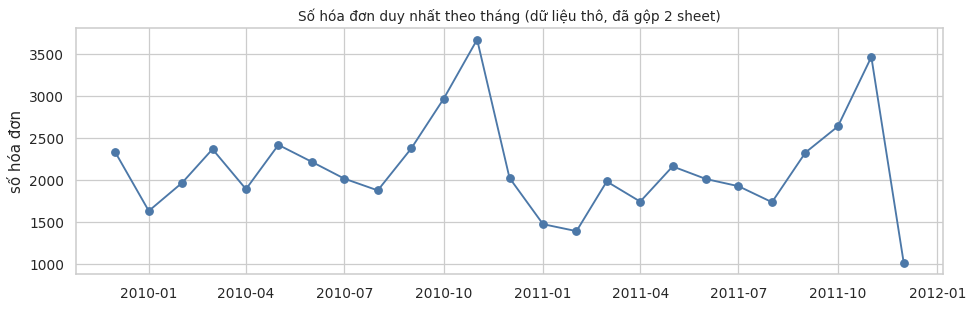

In [12]:
monthly = raw.assign(Month=raw["InvoiceDate"].dt.to_period("M").dt.to_timestamp()).groupby("Month")["Invoice"].nunique()
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(monthly.index, monthly.values, marker="o", color="#4C78A8")
ax.set_title("Số hóa đơn duy nhất theo tháng (dữ liệu thô, đã gộp 2 sheet)"); ax.set_ylabel("số hóa đơn")
plt.tight_layout(); plt.show()

**Nhận xét:** ~92% dòng thuộc Vương quốc Anh (43 nhãn quốc gia, có cả `Unspecified`, `European Community`) → `Country` rất lệch,
dùng làm đặc trưng phân cụm sẽ gần như hằng số; nên giữ làm thông tin mô tả chứ không đưa vào mô hình. Có 13 khách hàng gắn với hơn một quốc gia (không đáng kể).
Số hóa đơn có mùa vụ rõ (tăng từ tháng 9, đạt đỉnh tháng 11, giảm sau đó) và điểm cuối 12/2011 thấp vì dữ liệu chỉ có đến ngày 09/12 — cần nhớ khi chọn ngày tham chiếu tính *Recency*.

## 3. Xem phân phối bằng hình: histogram và boxplot

Dùng **dữ liệu thô** để thấy vấn đề, rồi dùng **dữ liệu sau khi bỏ lỗi nghiệp vụ** (chỉ dòng bán hợp lệ) để thấy ngoại lai thống kê thật sự.

### 3.1. Dữ liệu thô: Quantity và Price

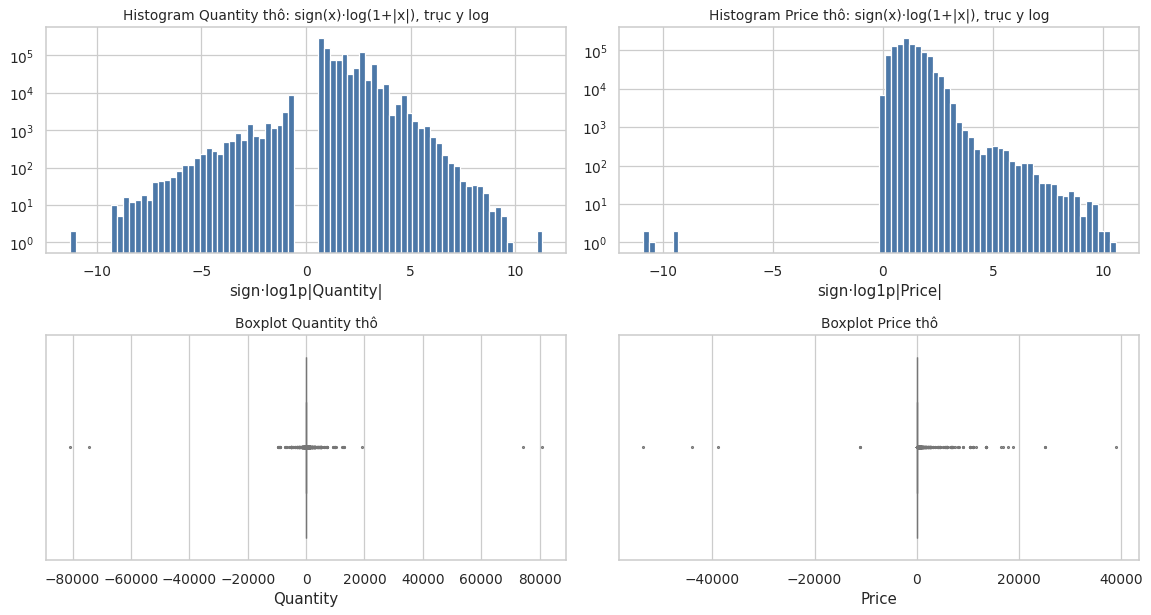

In [13]:
def symlog1p(x):
    return np.sign(x) * np.log1p(np.abs(x))

fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for j, col in enumerate(["Quantity", "Price"]):
    v = raw[col]
    axes[0, j].hist(symlog1p(v), bins=80, color="#4C78A8")
    axes[0, j].set_yscale("log")
    axes[0, j].set_title(f"Histogram {col} thô: sign(x)·log(1+|x|), trục y log")
    axes[0, j].set_xlabel(f"sign·log1p|{col}|")
    sns.boxplot(x=v, ax=axes[1, j], color="#A0CBE8", fliersize=1.5)
    axes[1, j].set_title(f"Boxplot {col} thô")
plt.tight_layout(); plt.show()

**Nhận xét:** histogram thô có cột ở cả phía âm lẫn bằng 0 (hủy, tặng, điều chỉnh). Boxplot bị "ép dẹt" thành một vạch sát 0 vì vài điểm quá lớn
(`Quantity` ±80.995, `Price` từ -53.594 đến +38.970) — các điểm này đều là hóa đơn hủy, phí `Manual`/`AMAZONFEE` hoặc điều chỉnh nợ xấu (ví dụ giá 38.970 thuộc hóa đơn hủy `C556445`, mã `M`).
Chưa thể kết luận gì về ngoại lai thống kê khi các lỗi nghiệp vụ còn lẫn trong dữ liệu.

### 3.2. Sau khi bỏ lỗi nghiệp vụ (chỉ dòng bán: Quantity > 0, Price > 0, mã hàng sản phẩm, có Customer ID)

In [14]:
tmp = pp.standardize(raw).drop_duplicates(subset=["Invoice","StockCode","Description","Quantity","InvoiceDate","Price","CustomerID","Country"])
tmp = tmp.dropna(subset=["CustomerID"])
tmp = tmp[~tmp["StockCode"].isin(pp.SERVICE_CODES) & ~tmp["Invoice"].str.startswith("C")]
tmp = tmp[(tmp["Quantity"] > 0) & (tmp["Price"] > 0)].assign(LineValue=lambda d: d["Quantity"] * d["Price"])
print("Số dòng bán hợp lệ trước khi xét ngoại lai:", len(tmp))

rows = []
for col in ["Quantity", "Price", "LineValue"]:
    s = tmp[col]; q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    hi = q3 + 1.5 * iqr
    s_log = np.log1p(s); l1, l3 = s_log.quantile([.25, .75]); lhi = l3 + 1.5 * (l3 - l1)
    rows.append({"Cột": col, "Skew": s.skew(), "Skew sau log1p": s_log.skew(),
                 "Q1": q1, "Median": s.median(), "Q3": q3, "Hàng rào trên (IQR)": hi,
                 "% trên hàng rào (thang gốc)": 100 * (s > hi).mean(),
                 "% trên hàng rào (thang log1p)": 100 * (s_log > lhi).mean(),
                 "P99": s.quantile(.99), "P99.9": s.quantile(.999), "Max": s.max()})
display(pd.DataFrame(rows).set_index("Cột").T)

Số dòng bán hợp lệ trước khi xét ngoại lai: 776596


Cột,Quantity,Price,LineValue
Skew,400.602,32.810,592.786
Skew sau log1p,0.873,0.763,0.431
Q1,2.000,1.250,4.950
Median,6.000,1.950,12.450
Q3,12.000,3.750,19.800
Hàng rào trên (IQR),27.000,7.500,42.075
% trên hàng rào (thang gốc),6.577,8.129,8.009
% trên hàng rào (thang log1p),1.217,0.874,1.970
P99,144.000,12.750,201.600
P99.9,576.000,34.950,832.804


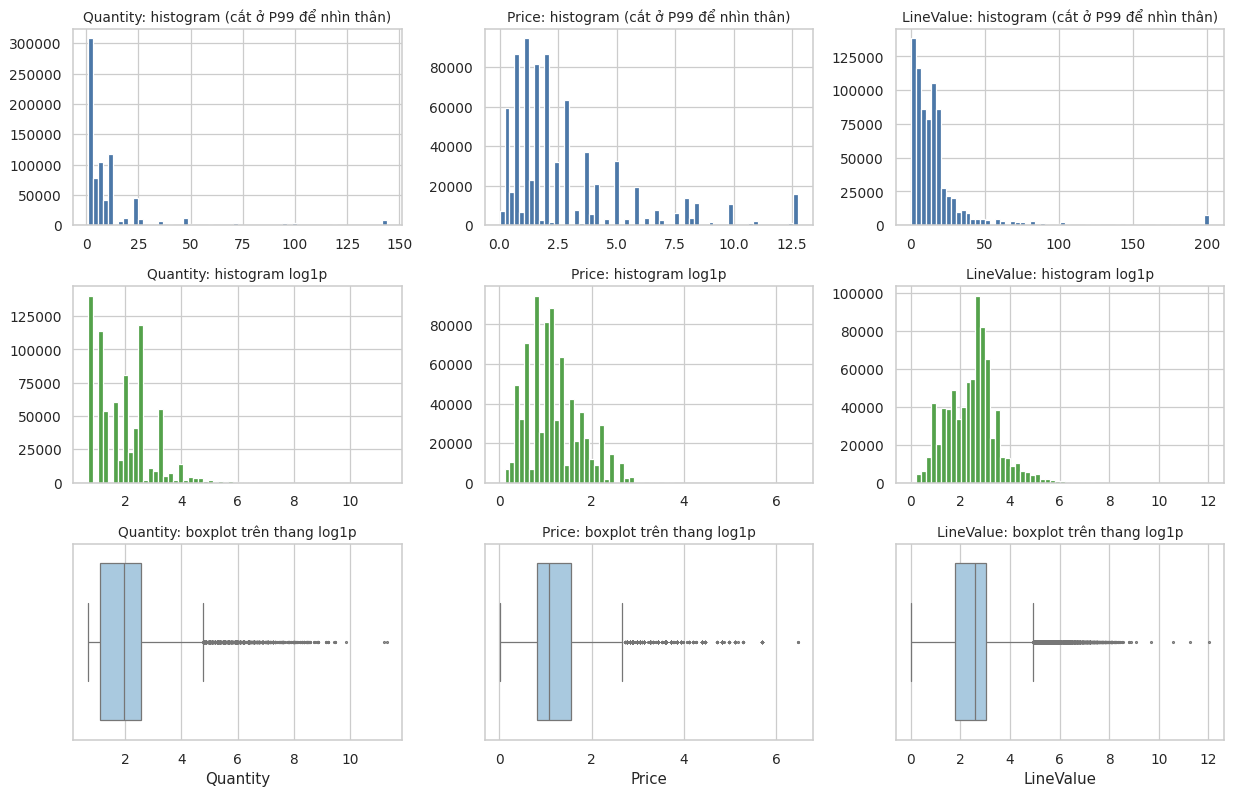

In [15]:
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for i, col in enumerate(["Quantity", "Price", "LineValue"]):
    v = tmp[col]
    axes[0, i].hist(v.clip(upper=v.quantile(.99)), bins=60, color="#4C78A8")
    axes[0, i].set_title(f"{col}: histogram (cắt ở P99 để nhìn thân)")
    axes[1, i].hist(np.log1p(v), bins=60, color="#54A24B")
    axes[1, i].set_title(f"{col}: histogram log1p")
    sns.boxplot(x=np.log1p(v), ax=axes[2, i], color="#A0CBE8", fliersize=1.5)
    axes[2, i].set_title(f"{col}: boxplot trên thang log1p")
plt.tight_layout(); plt.show()

**Nhận xét:**
- Sau khi bỏ lỗi nghiệp vụ, `Quantity`, `Price`, `LineValue` vẫn **lệch phải rất mạnh** (skew lớn) nhưng sau `log1p` skew giảm mạnh, histogram gần dạng chuông → dữ liệu gần **log-normal**.
- Trên thang gốc, hàng rào IQR gắn nhãn "ngoại lai" cho khoảng 6–8% số dòng (bảng trên) — phần lớn là **đơn sỉ hợp lệ** (khách mua theo thùng, ví dụ 12, 24, 144 cái), không phải lỗi. Cắt theo IQR thang gốc sẽ xóa đúng nhóm khách giá trị cao mà đề tài muốn tìm.
- Trên thang `log1p`, tỷ lệ vượt hàng rào giảm còn khoảng 1–2%; phần còn lại là những dòng cực lớn thật sự (hàng chục nghìn đơn vị).

### 3.3. Dòng cực trị về số lượng: lỗi nhập liệu hay đơn thật?

In [16]:
display(tmp.nlargest(10, "Quantity")[["Invoice", "StockCode", "Description", "Quantity", "Price", "CustomerID", "InvoiceDate"]])
display(tmp.nlargest(5, "Price")[["Invoice", "StockCode", "Description", "Quantity", "Price", "CustomerID"]])

cancels_tmp = pp.standardize(raw)
cancels_tmp = cancels_tmp[cancels_tmp["Invoice"].str.startswith("C") & cancels_tmp["CustomerID"].notna()]
display(Markdown("**Hóa đơn hủy đi kèm với các dòng cực trị**"))
display(cancels_tmp.nsmallest(5, "Quantity")[["Invoice", "StockCode", "Description", "Quantity", "Price", "CustomerID", "InvoiceDate"]])

,Invoice,StockCode,Description,Quantity,Price,CustomerID,InvoiceDate
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.080,"16,446.000",2011-12-09 09:15:00
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.040,"12,346.000",2011-01-18 10:01:00
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,0.100,"13,902.000",2010-02-15 11:57:00
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,0.100,"13,902.000",2010-03-17 13:09:00
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,0.100,"13,902.000",2010-03-17 13:09:00
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,0.100,"13,902.000",2010-03-17 13:09:00
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,0.100,"13,902.000",2010-03-17 13:09:00
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,0.250,"17,940.000",2010-03-23 15:36:00
135028,502269,21982,PACK OF 12 SUKI TISSUES,10000,0.250,"17,940.000",2010-03-23 15:36:00
135029,502269,21980,PACK OF 12 RED SPOTTY TISSUES,10000,0.250,"17,940.000",2010-03-23 15:36:00


,Invoice,StockCode,Description,Quantity,Price,CustomerID
748132,556444,22502,PICNIC BASKET WICKER 60 PIECES,60,649.500,"15,098.000"
748143,556446,22502,PICNIC BASKET WICKER 60 PIECES,1,649.500,"15,098.000"
268525,515349,22656,VINTAGE BLUE KITCHEN CABINET,1,295.000,"15,513.000"
268526,515349,22655,VINTAGE RED KITCHEN CABINET,1,295.000,"15,513.000"
270553,515602,22656,VINTAGE BLUE KITCHEN CABINET,1,295.000,"14,895.000"


**Hóa đơn hủy đi kèm với các dòng cực trị**

,Invoice,StockCode,Description,Quantity,Price,CustomerID,InvoiceDate
1065883,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.080,"16,446.000",2011-12-09 09:27:00
587085,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.040,"12,346.000",2011-01-18 10:17:00
507225,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,0.030,"15,838.000",2010-12-02 14:23:00
529729,C536757,84347,ROTATING SILVER ANGELS T-LIGHT HLDR,-9360,0.030,"15,838.000",2010-12-02 14:23:00
359669,C524235,21088,SET/6 FRUIT SALAD PAPER CUPS,-7128,0.080,"14,277.000",2010-09-28 11:02:00


**Nhận xét:** hai dòng lớn nhất (`80.995` cái và `74.215` cái) đều có **hóa đơn hủy cùng khách, cùng mã hàng, cùng số lượng** ngay sau đó
(`C581484`, `C541433`) → đơn nhập nhầm rồi hủy. Nếu giữ, hai khách này sẽ có Monetary khổng lồ giả tạo.
Các đơn 10.000–19.000 cái giá 0,10–0,25 £ của khách `13902` và `17940` là đơn sỉ giá rất rẻ, không bị hủy → là giao dịch thật, giữ lại.

## 4. Đề xuất phương án xử lý

| # | Vấn đề phát hiện | Phương án đề xuất | Lý do | Không chọn |
|---|---|---|---|---|
| 1 | Dòng trùng hoàn toàn (hai sheet chồng lấn + trùng nội bộ) | `drop_duplicates` trên 8 cột gốc | Trùng đến từng phút; bản sao chắc chắn | Giữ lại (làm Frequency/Monetary bị nhân đôi) |
| 2 | Thiếu `Customer ID` (~22,8%) | **Loại** khỏi dữ liệu phân cụm | RFM cần định danh khách; không thể điền hợp lý | Điền mean/mode/mã giả (tạo khách ảo) |
| 3 | Thiếu `Description` | Không cần điền: tất cả đã nằm trong nhóm bị loại ở #2 | Không dùng làm đặc trưng | — |
| 4 | Mã hàng dịch vụ (`POST`, `M`, `BANK CHARGES`, `AMAZONFEE`...) | Loại theo danh sách `SERVICE_CODES` | Không phải mua hàng; giá rất cao làm lệch Monetary | Giữ (nhiễu nặng) |
| 5 | Hóa đơn hủy (tiền tố `C`) | **Tách** sang `online_retail_cancellations.csv`, bảng bán hàng không chứa | Hoàn trả vẫn là thông tin hành vi cho RFM mở rộng; trộn chung làm tiền âm triệt tiêu Monetary | Xóa hẳn / giữ lẫn trong bảng bán |
| 6 | `Quantity <= 0` hoặc `Price <= 0` còn lại (hỏng, kiểm kho, tặng) | Loại khỏi bảng bán | Không phải giao dịch mua có doanh thu | Giữ |
| 7 | Đơn bán đã bị hủy nguyên vẹn (cùng khách, mã hàng, số lượng, giá, hủy sau mua) | Loại dòng bán tương ứng | Đây là ngoại lai do lỗi nhập; giữ sẽ làm Monetary khổng lồ giả | Cắt theo IQR |
| 8 | Ngoại lai thống kê còn lại (đơn sỉ lớn thật) | **Giữ nguyên ở mức dòng**; xử lý ở cấp khách hàng khi tạo RFM (biến đổi log, chuẩn hóa); DBSCAN gán nhãn nhiễu | Phân phối log-normal, IQR thang gốc xóa nhầm đơn sỉ hợp lệ, vốn là khách giá trị cao cần tìm | Xóa theo IQR/Z-score, winsorize ở mức dòng |
| 9 | Kiểu dữ liệu | `CustomerID` → `int`, `StockCode` viết hoa/trim, thêm `LineValue = Quantity × Price` | Thuận tiện nhóm theo khách và tính Monetary | — |

## 5. Thực hiện xử lý (từng bước, có đếm số dòng)

In [17]:
log = [("Dữ liệu gốc sau khi gộp sheet", len(raw))]
df = pp.standardize(raw)                       # trim, viết hoa mã, đổi 'Customer ID' -> 'CustomerID'
KEY = ["Invoice", "StockCode", "Description", "Quantity", "InvoiceDate", "Price", "CustomerID", "Country"]

# Bước 1. Bỏ dòng trùng
df = df.drop_duplicates(subset=KEY);                           log.append(("Bỏ dòng trùng hoàn toàn", len(df)))
# Bước 2. Bỏ dòng thiếu Customer ID
df = df.dropna(subset=["CustomerID"]).assign(CustomerID=lambda d: d["CustomerID"].astype(int))
log.append(("Bỏ dòng thiếu CustomerID", len(df)))
# Bước 3. Bỏ mã hàng dịch vụ
df = df[~df["StockCode"].isin(pp.SERVICE_CODES)];              log.append(("Bỏ mã hàng dịch vụ/phí/thử nghiệm", len(df)))
# Bước 4. Tách hóa đơn hủy
is_cancel = df["Invoice"].str.startswith("C")
cancels = df[is_cancel & (df["Quantity"] < 0) & (df["Price"] > 0)].copy()
sales = df[~is_cancel].copy();                                 log.append(("Tách hóa đơn hủy (tiền tố C) sang bảng riêng", len(sales)))
# Bước 5. Bỏ Quantity <= 0 / Price <= 0 trong bảng bán
sales = sales[(sales["Quantity"] > 0) & (sales["Price"] > 0)]; log.append(("Bỏ dòng bán có Quantity <= 0 hoặc Price <= 0", len(sales)))
# Bước 6. Thêm LineValue và bỏ đơn đã bị hủy nguyên vẹn
sales["LineValue"] = (sales["Quantity"] * sales["Price"]).round(2)
cancels["LineValue"] = (cancels["Quantity"] * cancels["Price"]).round(2)
rev = pp.reversed_sale_mask(sales, cancels)
removed_reversed = sales[rev]
sales = sales[~rev];                                           log.append(("Bỏ dòng bán đã bị hủy nguyên vẹn (đơn lỗi/ngoại lai)", len(sales)))

sales = sales.sort_values(["InvoiceDate", "Invoice"]).reset_index(drop=True)
cancels = cancels.sort_values(["InvoiceDate", "Invoice"]).reset_index(drop=True)
log_df = pd.DataFrame(log, columns=["Bước", "Số dòng còn lại"])
log_df["Số dòng bị loại"] = (-log_df["Số dòng còn lại"].diff()).fillna(0).astype(int)
display(log_df)
print("Các dòng bán bị loại vì đã bị hủy nguyên vẹn — lớn nhất:")
display(removed_reversed.nlargest(5, "LineValue")[["Invoice", "StockCode", "Quantity", "Price", "LineValue", "CustomerID"]])

,Bước,Số dòng còn lại,Số dòng bị loại
0,Dữ liệu gốc sau khi gộp sheet,1067371,0
1,Bỏ dòng trùng hoàn toàn,1033036,34335
2,Bỏ dòng thiếu CustomerID,797885,235151
3,Bỏ mã hàng dịch vụ/phí/thử nghiệm,794244,3641
4,Tách hóa đơn hủy (tiền tố C) sang bảng riêng,776657,17587
5,Bỏ dòng bán có Quantity <= 0 hoặc Price <= 0,776596,61
6,Bỏ dòng bán đã bị hủy nguyên vẹn (đơn lỗi/ngoạ...,770606,5990


Các dòng bán bị loại vì đã bị hủy nguyên vẹn — lớn nhất:


,Invoice,StockCode,Quantity,Price,LineValue,CustomerID
1065882,581483,23843,80995,2.080,"168,469.600",16446
587080,541431,23166,74215,1.040,"77,183.600",12346
578172,540815,21108,3114,2.100,"6,539.400",15749
578170,540815,85123A,1930,2.550,"4,921.500",15749
578233,540818,48185,670,6.750,"4,522.500",15749


**Lưu ý đọc bảng log:** dòng "Tách hóa đơn hủy" cho thấy số dòng còn lại của **bảng bán**; các dòng hủy không bị mất mà được giữ ở bảng `cancellations`.

## 6. Kiểm tra lại sau xử lý

In [18]:
# Kiểm tra độc lập: kết quả inline phải trùng với hàm trong src/preprocessing.py
s2, c2, l2 = pp.clean_transactions(raw)
assert s2.shape == sales.shape and c2.shape == cancels.shape
assert np.isclose(s2["LineValue"].sum(), sales["LineValue"].sum())
assert sales["CustomerID"].notna().all() and (sales["Quantity"] > 0).all() and (sales["Price"] > 0).all()
assert not sales["Invoice"].str.startswith("C").any() and not sales["StockCode"].isin(pp.SERVICE_CODES).any()
assert not sales.duplicated(subset=KEY).any()
print("Các kiểm tra hợp lệ.")

print(f"Bảng bán  : {sales.shape} | khách hàng: {sales['CustomerID'].nunique():,} | hóa đơn: {sales['Invoice'].nunique():,}")
print(f"Bảng hủy  : {cancels.shape} | khách hàng: {cancels['CustomerID'].nunique():,}")
print(f"Khoảng thời gian: {sales['InvoiceDate'].min()} → {sales['InvoiceDate'].max()}")
print(f"Tỷ lệ dòng giữ lại so với dữ liệu gốc: {len(sales)/len(raw):.1%}")
sales.info()
display(sales[["Quantity", "Price", "LineValue"]].describe(percentiles=[.25, .5, .75, .99]).T)
display(sales[["Quantity", "Price", "LineValue"]].skew().to_frame("Skew sau xử lý"))

Các kiểm tra hợp lệ.
Bảng bán  : (770606, 10) | khách hàng: 5,839 | hóa đơn: 36,414
Bảng hủy  : (17587, 10) | khách hàng: 2,445
Khoảng thời gian: 2009-12-01 07:45:00 → 2011-12-09 12:50:00
Tỷ lệ dòng giữ lại so với dữ liệu gốc: 72.2%
<class 'pandas.DataFrame'>
RangeIndex: 770606 entries, 0 to 770605
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   Invoice      770606 non-null  str           
 1   StockCode    770606 non-null  str           
 2   Description  770606 non-null  string        
 3   Quantity     770606 non-null  int64         
 4   InvoiceDate  770606 non-null  datetime64[us]
 5   Price        770606 non-null  float64       
 6   CustomerID   770606 non-null  int64         
 7   Country      770606 non-null  string        
 8   Sheet        770606 non-null  str           
 9   LineValue    770606 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(2), str(3), string(2)


,count,mean,std,min,25%,50%,75%,99%,max
Quantity,"770,606.000",13.118,73.227,1.000,2.000,6.000,12.000,128.000,"19,152.000"
Price,"770,606.000",2.916,4.145,0.001,1.250,1.950,3.750,12.750,649.500
LineValue,"770,606.000",21.440,81.205,0.000,4.950,11.900,19.500,195.600,"38,970.000"


,Skew sau xử lý
Quantity,95.315
Price,32.709
LineValue,167.727


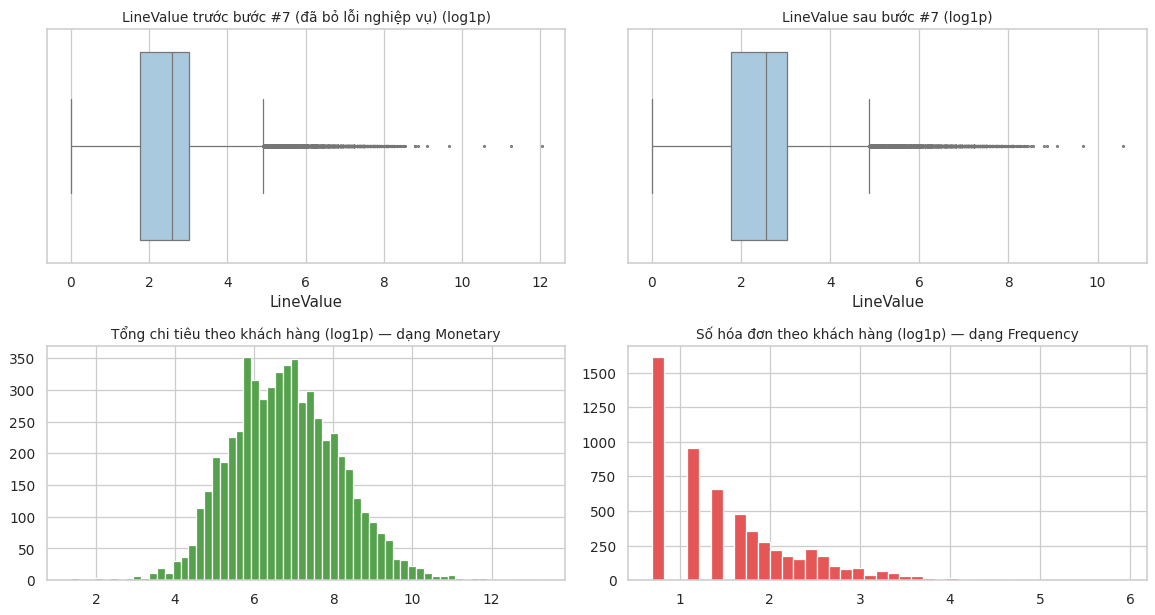

,count,mean,std,min,25%,50%,75%,99%,max
n_invoice,"5,839.000",6.236,12.677,1.000,1.000,3.000,7.000,46.000,371.000
spend,"5,839.000","2,829.612","13,900.574",2.900,336.245,851.010,"2,206.945","26,811.070","579,128.640"


,Skew cấp khách hàng (thang gốc)
n_invoice,11.975
spend,26.611


In [19]:
cust = sales.groupby("CustomerID").agg(n_invoice=("Invoice", "nunique"), spend=("LineValue", "sum"))
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
for ax, (raw_s, title) in zip(axes[0], [(tmp["LineValue"], "LineValue trước bước #7 (đã bỏ lỗi nghiệp vụ)"),
                                        (sales["LineValue"], "LineValue sau bước #7")]):
    sns.boxplot(x=np.log1p(raw_s), ax=ax, color="#A0CBE8", fliersize=1.5); ax.set_title(title + " (log1p)")
axes[1, 0].hist(np.log1p(cust["spend"]), bins=60, color="#54A24B")
axes[1, 0].set_title("Tổng chi tiêu theo khách hàng (log1p) — dạng Monetary")
axes[1, 1].hist(np.log1p(cust["n_invoice"]), bins=40, color="#E45756")
axes[1, 1].set_title("Số hóa đơn theo khách hàng (log1p) — dạng Frequency")
plt.tight_layout(); plt.show()
display(cust.describe(percentiles=[.25, .5, .75, .99]).T)
display(cust.skew().to_frame("Skew cấp khách hàng (thang gốc)"))

**Nhận xét sau xử lý:**
- Không còn giá trị thiếu, không trùng, không có hóa đơn hủy, số lượng/giá đều dương; tổng 770 nghìn dòng bán của khoảng 5,8 nghìn khách hàng.
- Ở cấp khách hàng, tổng chi tiêu và số hóa đơn vẫn **lệch phải rất mạnh** trên thang gốc, nhưng sau `log1p` skew giảm mạnh (chi tiêu ≈ 0,24; số hóa đơn ≈ 1,0) → với bước tạo RFM nên **áp dụng log (hoặc Box-Cox/Yeo-Johnson) trước khi chuẩn hóa**, đặc biệt trước khi chạy K-Means/DBSCAN vốn nhạy với khoảng cách.
- Ngoại lai còn lại là khách chi tiêu rất lớn (khách giá trị cao); **không xóa** ở bước này, để DBSCAN gán nhãn nhiễu và cluster profiling mô tả.

**Gợi ý bàn giao cho thành viên 2 (RFM):** dùng `online_retail_clean.csv` cho Recency/Frequency/Monetary; ngày tham chiếu nên là ngày sau giao dịch cuối cùng (dữ liệu kết thúc 09/12/2011);
dùng `online_retail_cancellations.csv` nếu muốn thêm đặc trưng hoàn trả (số hóa đơn hủy, giá trị hoàn).

## 7. Lưu dữ liệu vào `data/processed/`

In [20]:
pp.save_processed(sales, cancels, log_df.rename(columns={"Số dòng còn lại": "Số dòng còn lại"}), ROOT / "data" / "processed")
for f in sorted((ROOT / "data" / "processed").glob("*.csv")):
    print(f"{f.name:40s} {f.stat().st_size/1e6:8.2f} MB")

# Đọc lại để chắc chắn file ghi đúng
chk = pd.read_csv(ROOT / "data" / "processed" / "online_retail_clean.csv", parse_dates=["InvoiceDate"], dtype={"Invoice": str, "StockCode": str})
print("Đọc lại:", chk.shape, "| khớp số dòng:", len(chk) == len(sales), "| tổng LineValue khớp:", np.isclose(chk["LineValue"].sum(), sales["LineValue"].sum()))
display(chk.head())

online_retail_cancellations.csv              1.95 MB
online_retail_clean.csv                     83.46 MB
preprocessing_log.csv                        0.00 MB


Đọc lại: (770606, 10) | khớp số dòng: True | tổng LineValue khớp: True


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,CustomerID,Country,Sheet,LineValue
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,13085,United Kingdom,Year 2009-2010,83.400
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085,United Kingdom,Year 2009-2010,81.000
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,13085,United Kingdom,Year 2009-2010,81.000
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,13085,United Kingdom,Year 2009-2010,100.800
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,13085,United Kingdom,Year 2009-2010,30.000


### Dữ liệu đầu ra

| Tệp | Nội dung | Dùng cho |
|---|---|---|
| `online_retail_clean.csv` | Dòng bán hợp lệ, có `CustomerID`, thêm `LineValue` | Tạo RFM, phân cụm |
| `online_retail_cancellations.csv` | Dòng hóa đơn hủy có `CustomerID` (Quantity âm) | Đặc trưng hoàn trả (tùy chọn) |
| `preprocessing_log.csv` | Số dòng còn lại sau mỗi bước | Báo cáo chương 2 |